# CNN Development on Custom Dataset — Fresh vs Rotten Fruits Classification
**Course:** CVPR  |  **Student ID:** `23-50232-1`  |  **Framework:** PyTorch

**Objective:** Design and train a custom CNN that classifies fruit images into 6 classes (fresh / rotten × apple / banana / orange).

**Dataset:** [Fruits fresh and rotten for classification (Kaggle)](https://www.kaggle.com/datasets/sriramr/fruits-fresh-and-rotten-for-classification)

**Notebook structure**
1. Import Libraries
2. Load and Explore Dataset
3. Data Preprocessing & Augmentation
4. Define CNN Architecture
5. Training Loop with Validation
6. Evaluate Model on Test Set
7. Visualizations (Loss/Accuracy Curves)
8. Save and Load Model
9. Analysis & Discussion of Results
10. Conclusions & Future Work

## 1. Import Libraries
All libraries used in the notebook are imported here. The `device` line selects the GPU when available (in Colab: *Runtime → Change runtime type → T4 GPU*) so training is much faster.

In [1]:
# ---------------------------------------------------------------
# SECTION 1: IMPORT LIBRARIES
# ---------------------------------------------------------------
from torchvision import datasets
import torchvision.transforms as transforms

from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn

import os
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# Use GPU if available, otherwise CPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


## 2. Load and Explore Dataset
**Dataset description**
- Source: Kaggle (`sriramr/fruits-fresh-and-rotten-for-classification`)
- Content: RGB photos of apples, bananas and oranges, each labelled *fresh* or *rotten*
- Classes (6): `freshapples`, `freshbanana`, `freshoranges`, `rottenapples`, `rottenbanana`, `rottenoranges`
- Folder layout: `dataset/train/<class>/` and `dataset/test/<class>/`

The dataset is downloaded with `kagglehub` (no API key needed for public datasets).

In [2]:
# ---------------------------------------------------------------
# SECTION 2: LOAD DATASET (download from Kaggle using kagglehub)
# ---------------------------------------------------------------
import kagglehub
path = kagglehub.dataset_download("sriramr/fruits-fresh-and-rotten-for-classification")
print("Path to dataset files:", path)

# Find the 'train' and 'test' folders automatically (folder nesting can differ between versions)
for root, dirs, files in os.walk(path):
    if 'train' in dirs and 'test' in dirs:
        dataset_root = root
        break
print("Dataset root:", dataset_root)

Using Colab cache for faster access to the 'fruits-fresh-and-rotten-for-classification' dataset.
Path to dataset files: /kaggle/input/fruits-fresh-and-rotten-for-classification
Dataset root: /kaggle/input/fruits-fresh-and-rotten-for-classification/dataset


## 3. Data Preprocessing & Augmentation
- **Image size = 32 × 32** (all images are resized to the same size so they can be batched).
- **Training transform (with augmentation):** horizontal flip, rotation ±15°, and a *mild* colour jitter. Augmentation acts as a regulariser — it creates new variations every epoch and reduces over-fitting. Colour jitter is kept small because colour/darkness is the main cue that separates fresh from rotten fruit.
- **Validation / Test transform:** only resize + `ToTensor` (no random changes, so evaluation is deterministic).
- **Split:** the dataset already has `train` and `test` folders. As in the example notebook, the original test folder is split 50 % / 50 % into **validation** and **test** sets (fixed random seed for reproducibility).
- **Batch size = 32.**

In [3]:
# ---------------------------------------------------------------
# SECTION 3: PREPROCESSING & AUGMENTATION
# ---------------------------------------------------------------
import torchvision.transforms as transforms
from torch.utils.data import random_split

size = 32   # input image size (32 x 32)

# Training transform: resize + augmentation
train_transform = transforms.Compose([
    transforms.Resize((size, size)),        # resize to model input size
    transforms.RandomHorizontalFlip(),      # horizontal flip augmentation
    transforms.RandomRotation(15),          # rotate +-15 degrees
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),  # mild colour change
    transforms.ToTensor()                   # convert PIL -> float tensor [0.0,1.0]
])

# Validation / test transform: NO augmentation
val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

train_folder = dataset_root + '/train'
test_folder = dataset_root + '/test'

# ImageFolder: each sub-folder name becomes a class label
train_data = datasets.ImageFolder(train_folder, transform = train_transform)
val_test_data = datasets.ImageFolder(test_folder, transform = val_transform)

# Split original test dataset into validation (50%) and test (50%)
val_size = len(val_test_data) // 2
test_size = len(val_test_data) - val_size

val_data, test_data = random_split(
    val_test_data,
    [val_size, test_size],
    generator = torch.Generator().manual_seed(42)   # fixed seed -> same split every run
)

In [4]:
# Dataset summary
print('Dataset Summary')
print('Train Data: ', len(train_data))
print('Validation Data: ', len(val_data))
print('Test Data: ', len(test_data))
print('Classess and Indices: ' , train_data.class_to_idx)
num_classes = len(train_data.classes)   # number of output classes (6)
print('Number of classes: ', num_classes)

Dataset Summary
Train Data:  10901
Validation Data:  1349
Test Data:  1349
Classess and Indices:  {'freshapples': 0, 'freshbanana': 1, 'freshoranges': 2, 'rottenapples': 3, 'rottenbanana': 4, 'rottenoranges': 5}
Number of classes:  6


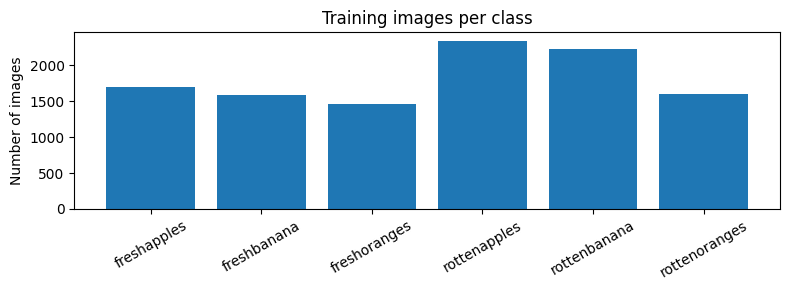

{'freshapples': np.int64(1693), 'freshbanana': np.int64(1581), 'freshoranges': np.int64(1466), 'rottenapples': np.int64(2342), 'rottenbanana': np.int64(2224), 'rottenoranges': np.int64(1595)}


In [5]:
# Class distribution of the training set (check for class imbalance)
counts = np.bincount(train_data.targets, minlength=num_classes)
plt.figure(figsize=(8, 3))
plt.bar(train_data.classes, counts)
plt.title("Training images per class")
plt.xticks(rotation=30)
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()
print(dict(zip(train_data.classes, counts)))

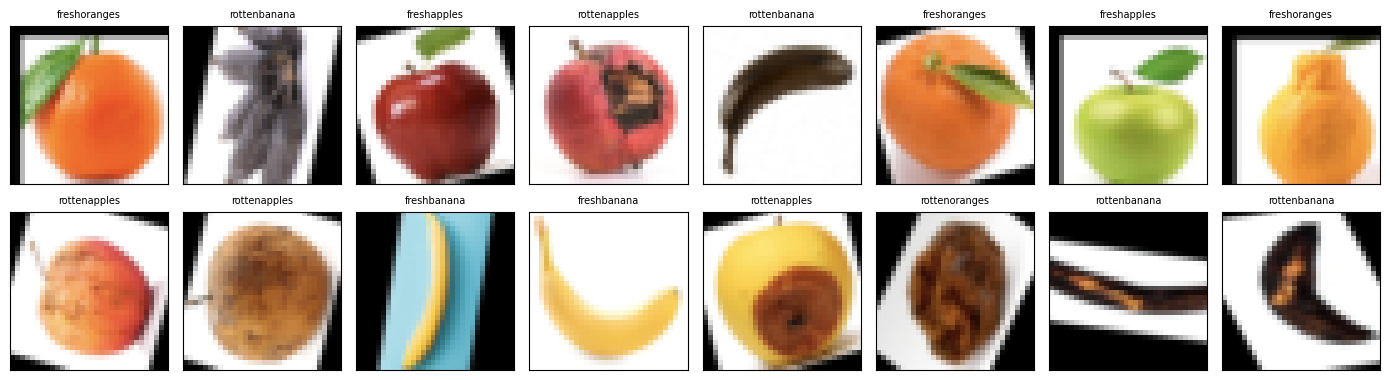

In [6]:
# Show a few random sample images (after resizing to 32x32) with their labels
ROWS, COLS = 2, 8
fig, axes = plt.subplots(ROWS, COLS, figsize=(14, 4))
for ax in axes.flat:
    img, label = val_test_data[np.random.randint(0, len(val_test_data))]
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(val_test_data.classes[label], fontsize=7)
    ax.set(xticks=[], yticks=[])
plt.tight_layout()
plt.show()

### Hyperparameters and rationale
| Hyperparameter | Value | Rationale |
|---|---|---|
| Image size | 32 × 32 | Required input size; small images keep training fast |
| Batch size | 32 | Required; good balance of gradient noise (helps generalisation) and speed |
| Hidden layer (fully connected) | 256 | Required; enough capacity to combine the conv features |
| Optimizer | Adam | Adaptive learning rate, converges fast and reliably on image data |
| Learning rate | 1e-3 | Standard starting value for Adam; reduced automatically by the scheduler when validation loss stops improving |
| Weight decay | 1e-4 | L2 regularisation to limit over-fitting |
| Dropout | 0.25 (conv) / 0.5 (FC) | Randomly drops units so the network does not memorise the training set |
| Epochs | 30 | Enough for convergence; the best epoch (highest validation accuracy) is kept |
| Loss | Cross-Entropy | Standard loss for multi-class classification |

In [7]:
# ---------------------------------------------------------------
# HYPERPARAMETERS
# ---------------------------------------------------------------
batch_size = 32          # number of images per batch
learning_rate = 1e-3     # initial learning rate for Adam
epoch_number = 30        # number of training epochs
hidden_size = 256        # neurons in the fully connected hidden layer
weight_decay = 1e-4      # L2 regularisation strength

In [8]:
# ---------------------------------------------------------------
# DATA LOADERS (train is shuffled, validation/test are not)
# ---------------------------------------------------------------
trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

# Check one batch shape: [batch, channels, height, width]
x_batch, y_batch = next(iter(trn_dl))
print("Batch of images:", x_batch.shape, "| Batch of labels:", y_batch.shape)

Batch of images: torch.Size([32, 3, 32, 32]) | Batch of labels: torch.Size([32])


## 4. Define CNN Architecture
**Design (3 convolutional blocks + classifier):**

| Block | Layers | Output size |
|---|---|---|
| Input | RGB image | 3 × 32 × 32 |
| Block 1 | 2 × (Conv 3×3, 64 filters + BatchNorm + ReLU) → MaxPool | 64 × 16 × 16 |
| Block 2 | 2 × (Conv 3×3, 128 filters + BatchNorm + ReLU) → MaxPool → Dropout | 128 × 8 × 8 |
| Block 3 | Conv 3×3, 256 filters + BatchNorm + ReLU → MaxPool → Dropout | 256 × 4 × 4 |
| Classifier | Flatten → Linear(4096 → **256**) → ReLU → Dropout → Linear(256 → 6) | 6 logits |

**Justification**
- **Conv layers** learn spatial features: edges/texture in early layers (e.g. bruised spots, skin pattern), colour and shape combinations in deeper layers.
- **Filters double (64 → 128 → 256)** while the image size halves — deeper layers need more feature maps to describe more complex patterns.
- **`padding=1`** keeps the size unchanged inside a block, so no information at the borders is lost on a small 32×32 image.
- **BatchNorm** stabilises and speeds up training and allows a higher learning rate.
- **ReLU** is a simple non-linearity that avoids vanishing gradients.
- **MaxPool** halves the resolution, reduces computation and gives small translation invariance.
- **Dropout** reduces over-fitting.
- **Output layer has 6 neurons (raw logits)** — `nn.CrossEntropyLoss` applies softmax internally.

In [9]:
# ---------------------------------------------------------------
# SECTION 4: CNN ARCHITECTURE
# get_model() returns the model, the loss function and the optimizer
# ---------------------------------------------------------------
from torch.optim import SGD, Adam
def get_model():
    model = nn.Sequential(
        # ---------- Feature Extraction ----------
        # Block 1: 3x32x32 -> 64x16x16
        nn.Conv2d(3, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.Conv2d(64, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Block 2: 64x16x16 -> 128x8x8
        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.Conv2d(128, 128, kernel_size=3, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Dropout(0.25),

        # Block 3: 128x8x8 -> 256x4x4
        nn.Conv2d(128, 256, kernel_size=3, padding=1),
        nn.BatchNorm2d(256),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Dropout(0.25),

        # ---------- Classifier ----------
        nn.Flatten(),                         # 256*4*4 = 4096 features
        nn.Linear(256*4*4, hidden_size),      # hidden layer = 256
        nn.ReLU(),
        nn.Dropout(0.5),
        nn.Linear(hidden_size, num_classes)   # 6 output classes (logits)
    ).to(device)

    # Cross-entropy loss for multi-class classification
    loss_fn = nn.CrossEntropyLoss()
    # Adam optimizer with L2 weight decay
    optimizer = Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    return model, loss_fn, optimizer

In [ ]:
# Detailed model summary (layers, output shapes, number of parameters)
!pip install -q torchsummary
from torchsummary import summary
model, loss_fn, optimizer = get_model()
summary(model, input_size=(3,32,32));

## 5. Training Loop with Validation
- `train_one_epoch`: one pass over the training data (forward → loss → backward → optimizer step).
- `validation`: evaluates on validation/test data with gradients disabled (`@torch.no_grad()`) and `model.eval()` (turns off Dropout and fixes BatchNorm).
- **Learning-rate scheduler (`ReduceLROnPlateau`)**: halves the learning rate when the validation loss does not improve for 3 epochs — big steps early, fine steps later for better final accuracy.
- **Best-model checkpoint:** the weights of the epoch with the highest validation accuracy are kept and used for the final test.

In [10]:
# ---------------------------------------------------------------
# SECTION 5: TRAINING & VALIDATION FUNCTIONS
# ---------------------------------------------------------------
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()                                  # enable dropout / batchnorm training mode
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)          # move batch to GPU/CPU

        optimizer.zero_grad()                      # clear old gradients
        prediction = model(x)                      # forward pass
        batch_loss = loss_fn(prediction, y)        # cross-entropy loss
        batch_loss.backward()                      # back-propagation
        optimizer.step()                           # update weights

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()   # correct predictions in batch
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)

@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()                                   # disable dropout, freeze batchnorm stats
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)          # move to device here
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

In [11]:
# ---------------------------------------------------------------
# TRAINING LOOP (30 epochs)
# ---------------------------------------------------------------
import copy

# Create a fresh model, loss function and optimizer
model, loss_fn, optimizer = get_model()

# Reduce learning rate by half if validation loss does not improve for 3 epochs
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

best_val_acc = 0.0                       # best validation accuracy seen so far
best_weights = copy.deepcopy(model.state_dict())

for epoch in range(epoch_number):
  epoch_loss, epoch_accuracy = train_one_epoch(trn_dl,model,loss_fn,optimizer)
  train_losses.append(epoch_loss)
  train_accuracies.append(epoch_accuracy)

  v_loss, v_acc =  validation(val_dl,model,loss_fn)
  val_losses.append(v_loss)
  val_accuracies.append(v_acc)

  scheduler.step(v_loss)                 # adjust learning rate using validation loss

  # Keep the weights of the best epoch (highest validation accuracy)
  if v_acc > best_val_acc:
      best_val_acc = v_acc
      best_weights = copy.deepcopy(model.state_dict())

  print(f"Epoch [{epoch + 1}/{epoch_number}]"
        f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
        f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%"
        f" | LR: {optimizer.param_groups[0]['lr']:.6f}")

print(f"\nBest Validation Accuracy: {best_val_acc*100:.2f}%")

Epoch [1/30] | Train Loss: 0.7403 | Train Accuracy: 73.79% | Val Loss: 0.3611 | Val Accuracy: 89.40% | LR: 0.001000
Epoch [2/30] | Train Loss: 0.4271 | Train Accuracy: 85.32% | Val Loss: 0.3006 | Val Accuracy: 89.25% | LR: 0.001000
Epoch [3/30] | Train Loss: 0.3291 | Train Accuracy: 88.88% | Val Loss: 0.1838 | Val Accuracy: 93.40% | LR: 0.001000
Epoch [4/30] | Train Loss: 0.2918 | Train Accuracy: 90.36% | Val Loss: 0.3594 | Val Accuracy: 88.88% | LR: 0.001000
Epoch [5/30] | Train Loss: 0.2574 | Train Accuracy: 91.28% | Val Loss: 0.1701 | Val Accuracy: 94.37% | LR: 0.001000
Epoch [6/30] | Train Loss: 0.2296 | Train Accuracy: 92.28% | Val Loss: 0.1794 | Val Accuracy: 93.85% | LR: 0.001000
Epoch [7/30] | Train Loss: 0.2069 | Train Accuracy: 93.19% | Val Loss: 0.1402 | Val Accuracy: 95.40% | LR: 0.001000
Epoch [8/30] | Train Loss: 0.1928 | Train Accuracy: 93.57% | Val Loss: 0.1488 | Val Accuracy: 94.37% | LR: 0.001000
Epoch [9/30] | Train Loss: 0.1713 | Train Accuracy: 94.22% | Val Loss: 0

## 6. Evaluate Model on Test Set
The best checkpoint (highest validation accuracy) is loaded and evaluated **once** on the unseen test set. Besides accuracy we report precision, recall and F1-score per class and a confusion matrix, because accuracy alone can hide which classes are confused.

In [12]:
# ---------------------------------------------------------------
# SECTION 6: TEST SET EVALUATION
# ---------------------------------------------------------------
model.load_state_dict(best_weights)      # load the best epoch's weights

test_loss, test_acc =  validation(test_dl,model,loss_fn)
print(f'Test Loss : {test_loss:0.4f} , Test Accuracy: {test_acc*100:0.2f}%')

Test Loss : 0.0064 , Test Accuracy: 99.70%


               precision    recall  f1-score   support

  freshapples     0.9948    1.0000    0.9974       193
  freshbanana     1.0000    1.0000    1.0000       185
 freshoranges     1.0000    0.9904    0.9952       208
 rottenapples     0.9966    0.9966    0.9966       295
 rottenbanana     1.0000    1.0000    1.0000       275
rottenoranges     0.9897    0.9948    0.9922       193

     accuracy                         0.9970      1349
    macro avg     0.9969    0.9970    0.9969      1349
 weighted avg     0.9970    0.9970    0.9970      1349



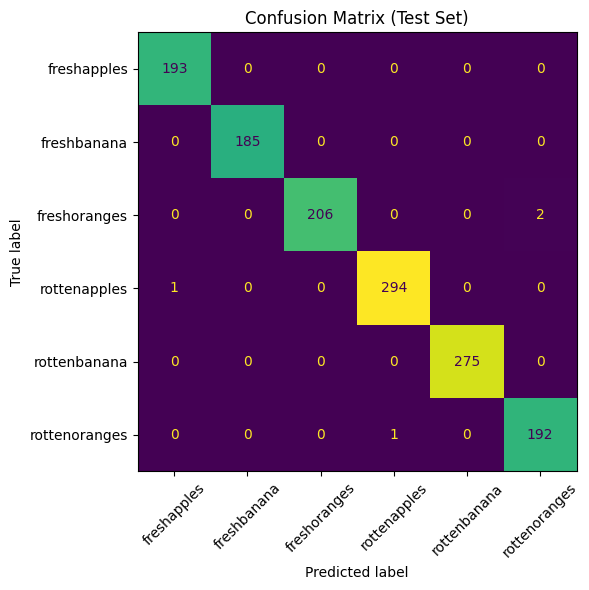

In [13]:
# Per-class metrics (precision, recall, F1) and confusion matrix
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

@torch.no_grad()
def get_predictions(data_loader, model):
    model.eval()
    all_preds, all_labels = [], []
    for x, y in data_loader:
        x = x.to(device)
        all_preds.extend(model(x).argmax(-1).cpu().tolist())   # predicted class
        all_labels.extend(y.tolist())                          # true class
    return all_labels, all_preds

y_true, y_pred = get_predictions(test_dl, model)
print(classification_report(y_true, y_pred, target_names=train_data.classes, digits=4))

fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=train_data.classes).plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("Confusion Matrix (Test Set)")
plt.tight_layout()
plt.show()

True label: freshoranges


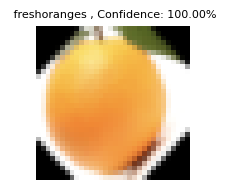

In [14]:
# Predict a single test image with confidence (softmax probability)
@torch.no_grad()
def predictOne(model, img, classes = None):
  model.eval()
  img = img.view(-1,3,size,size).to(device)
  output = model(img)
  pred = torch.exp(output)/torch.sum(torch.exp(output))     # softmax
  confidence, index = pred.max(-1)
  plt.figure(figsize=(2,2))
  plt.imshow(img.view(3,size,size).permute(1,2,0).cpu().numpy())
  plt.title(f' {classes[index]} , Confidence: {confidence.item()*100:0.2f}%', fontsize=8)
  plt.axis('off')
  plt.show()

test_img, label = test_data[2]
print("True label:", train_data.classes[label])
predictOne(model, test_img, train_data.classes)

## 7. Visualizations (Loss/Accuracy Curves)
Training and validation loss/accuracy are plotted per epoch. They show how fast the model learns, whether it over-fits (training keeps improving while validation stalls or worsens) and whether training has converged.

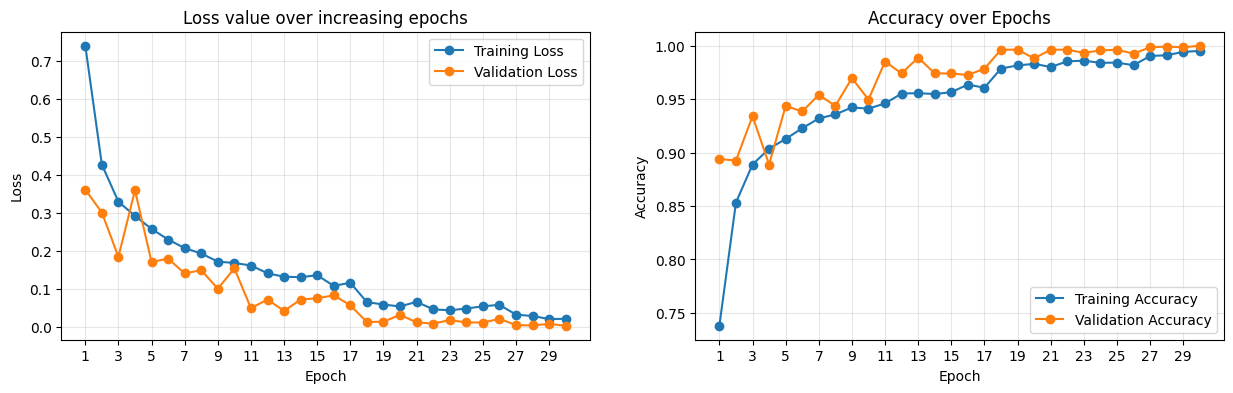

In [15]:
# ---------------------------------------------------------------
# SECTION 7: LOSS & ACCURACY CURVES
# ---------------------------------------------------------------
epochs = np.arange(epoch_number) + 1
plt.figure(figsize=(15, 4))
plt.subplot(121)
plt.title("Loss value over increasing epochs")
plt.plot(epochs, train_losses, marker='o', label="Training Loss")
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs[::2])
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)
plt.title("Accuracy over Epochs")
plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs[::2])
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 8. Save and Load Model
Only the weights (`state_dict`) are saved to a `.pth` file. To reuse the model, create the same architecture with `get_model()` and load the weights. The loaded model must give the same test accuracy as the original (sanity check). Per the assignment: if the file is larger than 20 MB, keep it locally and do not upload it to GitHub.

In [16]:
# ---------------------------------------------------------------
# SECTION 8: SAVE THE TRAINED MODEL WEIGHTS (.pth)
# ---------------------------------------------------------------
torch.save(model.state_dict(),'model.pth')
print("Model size: %.2f MB" % (os.path.getsize('model.pth')/1024/1024))

# Optional (Colab): download the file to your computer
# from google.colab import files
# files.download('model.pth')

Model size: 6.15 MB


In [18]:
# Load the saved weights into a new model and verify the test accuracy is the same
!pip install -q torchsummary
from torchsummary import summary

saved_model, saved_loss_fn, _ = get_model()
saved_model.load_state_dict(torch.load('model.pth', map_location=device))
saved_model.eval()
summary(saved_model,(3,32,32))

t_loss, t_acc = validation(test_dl, saved_model, saved_loss_fn)
print(f'Loaded Model -> Test Loss : {t_loss:0.4f} , Test Accuracy: {t_acc*100:0.2f}%')

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 32, 32]           1,792
       BatchNorm2d-2           [-1, 64, 32, 32]             128
              ReLU-3           [-1, 64, 32, 32]               0
            Conv2d-4           [-1, 64, 32, 32]          36,928
       BatchNorm2d-5           [-1, 64, 32, 32]             128
              ReLU-6           [-1, 64, 32, 32]               0
         MaxPool2d-7           [-1, 64, 16, 16]               0
            Conv2d-8          [-1, 128, 16, 16]          73,856
       BatchNorm2d-9          [-1, 128, 16, 16]             256
             ReLU-10          [-1, 128, 16, 16]               0
           Conv2d-11          [-1, 128, 16, 16]         147,584
      BatchNorm2d-12          [-1, 128, 16, 16]             256
             ReLU-13          [-1, 128, 16, 16]               0
        MaxPool2d-14            [-1, 12

## 9. Analysis & Discussion of Results

- **Final results:** Best validation accuracy = `100.00 %` (epoch 30), Test accuracy = `99.70 %` (1345 of 1349 images correct), Test loss = `0.0064`. The reloaded `model.pth` gave the same test accuracy, so saving and loading works correctly.
- **Learning curves:** Training and validation curves stay close, so there is no over-fitting. Validation accuracy is sometimes higher than training accuracy because Dropout and augmentation are active only during training. In the first 16 epochs, validation loss is noisy (e.g. epoch 4: 0.3594, epoch 11: 0.0488). The scheduler halved the learning rate to 0.0005 after epoch 17 and to 0.00025 after epoch 26. Each reduction gave a clear improvement: validation accuracy rose from 97.85% to 99.63% right after the first one, and loss dropped smoothly to 0.0024 by epoch 30. The curves were still improving at the end, so the best checkpoint was the final epoch.
- **Per-class metrics:** Precision, recall and F1 are all between 0.990 and 1.000. `freshbanana` and `rottenbanana` were classified perfectly. Only 4 test images were wrong: 2 `freshoranges`, 1 `rottenapples` and 1 `rottenoranges`. The weakest class was `rottenoranges` (F1 = 0.9922), probably because slightly spoiled oranges look similar to fresh ones at 32×32, where small spots are lost.
- **Effect of design choices:**
  - BatchNorm + Adam gave fast, stable convergence (89% validation accuracy after epoch 1).
  - Dropout + augmentation + weight decay kept the training/validation gap small.
  - The LR scheduler gave the largest gain, because smaller steps let the model settle into a better minimum.
  - Validation accuracy (100%) is slightly optimistic because the best checkpoint was chosen on it, so the test accuracy of 99.70% on unseen data is the reliable figure.

## 10. Conclusions & Future Work

**Conclusion:** A custom 5-convolution-layer CNN with BatchNorm, Dropout and a 256-unit hidden layer (1.6M parameters, 6.13 MB) was trained on the fresh/rotten fruit dataset using Adam and cross-entropy loss for 30 epochs, with batch size 32 and image size 32×32. The model reached **99.70% test accuracy** (macro F1 = 0.9969). The weights were saved to `model.pth` and reloaded successfully with identical results.

**Limitations:** 32×32 inputs lose fine detail (small spots/mould), which caused the few remaining errors on oranges and apples. The dataset covers only three fruit types and has fairly clean backgrounds, so the model may perform worse on real-world photos with cluttered scenes or different lighting.

**Future work:**
- Use higher resolution (64×64 or 128×128) to keep texture detail.
- Try transfer learning with a pre-trained network (ResNet18 / MobileNet).
- Train longer, since the curves were still improving at epoch 30.
- Add stronger augmentation and more fruit types, and test on real-world images.